# BiblioDAO - demo del DAO

Base de Datos II - UNdeC

Demo del sistema de prestamos de la biblioteca. El notebook solo usa los metodos
de `BibliotecaDAO`, no hay SQL ni conexiones directas a las bases.

Bases que usa:
- Oracle: socios, libros, ejemplares, prestamos y multas
- MongoDB: resenas y auditoria
- Redis: ranking de prestamos, cache de disponibilidad y contadores

Antes de correrlo hay que levantar los contenedores con `docker compose up -d`.
La primera celda vuelve a cargar los datos de prueba, asi que se puede correr
completo varias veces (Kernel > Restart & Run All).

## 0. Preparacion

In [1]:
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

import config_vars
import crear_bd
from dao import BibliotecaDAO, BibliotecaError

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)


def tabla(filas, columnas=None):
    df = pd.DataFrame(filas)
    return df[columnas] if columnas and not df.empty else df


def debe_fallar(descripcion, accion):
    # para probar las validaciones: la accion tiene que tirar BibliotecaError
    try:
        accion()
        print(f"{descripcion}: NO dio error y deberia")
    except BibliotecaError as e:
        print(f"{descripcion} -> {e}")

In [2]:
# vuelve a cargar los datos de prueba en oracle, mongo y redis
RESETEAR = True
if RESETEAR:
    crear_bd.main()

  socios      5 filas
  autores     5 filas
  libros      6 filas
  ejemplares  11 filas
  prestamos   4 filas
  multas      1 filas
Listo: 47 sentencias ejecutadas.


  resenas (Mongo)                4
  eventos de auditoria (Mongo)   0
  libros en el ranking (Redis)   3
  claves del proyecto (Redis)    1
Listo: MongoDB y Redis preparados.


In [3]:
dao = BibliotecaDAO()

with dao.engine.connect() as con:
    usuario = con.execute(text("SELECT USER FROM dual")).scalar()
    version = con.execute(text("SELECT banner FROM v$version")).scalar()

print("Oracle:", usuario, "-", version)
print("MongoDB:", dao.mongo.client.server_info()["version"], "- base", dao.mongo.name)
print("Redis:", dao.redis.info()["redis_version"], "- ping", dao.redis.ping())

Oracle: BIBLIO - Oracle Database 21c Express Edition Release 21.0.0.0.0 - Production
MongoDB: 7.0.45 - base biblioteca
Redis: 7.4.12 - ping True


In [4]:
# reglas de negocio (estan en config_vars.py)
print("Dias de prestamo:", config_vars.DIAS_PRESTAMO)
print("Maximo de prestamos a la vez:", config_vars.MAX_PRESTAMOS_ACTIVOS)
print("Multa por dia de atraso: $", config_vars.MULTA_POR_DIA)

Dias de prestamo: 14
Maximo de prestamos a la vez: 3
Multa por dia de atraso: $ 500


In [5]:
resumen_inicial = dao.resumen()
resumen_inicial

{'socios_activos': 5,
 'libros': 6,
 'prestamos_activos': 2,
 'prestamos_vencidos': 1,
 'multas_pendientes': 1}

## 1. Catalogo

In [6]:
tabla(dao.listar_libros(), ["lib_id", "titulo", "autor", "categoria", "anio"])

,lib_id,titulo,autor,categoria,anio
0,2,El Aleph,Jorge Luis Borges,Literatura,1949
1,1,Ficciones,Jorge Luis Borges,Literatura,1944
2,5,Fundamentos de Bases de Datos,Abraham Silberschatz,Informatica,2006
3,4,Fundamentos de Sistemas de Bases de Datos,Ramez Elmasri,Informatica,2007
4,6,Ingenieria de Software,Ian Sommerville,Informatica,2011
5,3,Rayuela,Julio Cortazar,Literatura,1963


In [7]:
# busqueda por texto, no importan mayusculas
tabla(dao.buscar_libros("BASES"), ["lib_id", "titulo", "autor"])

,lib_id,titulo,autor
0,5,Fundamentos de Bases de Datos,Abraham Silberschatz
1,4,Fundamentos de Sistemas de Bases de Datos,Ramez Elmasri


In [8]:
tabla(dao.listar_libros(categoria="Literatura"), ["lib_id", "titulo", "autor"])

,lib_id,titulo,autor
0,2,El Aleph,Jorge Luis Borges
1,1,Ficciones,Jorge Luis Borges
2,3,Rayuela,Julio Cortazar


In [9]:
# copias de cada libro segun su estado
disponibilidad = tabla([
    {"titulo": l["titulo"], **dao.disponibilidad(l["lib_id"])}
    for l in dao.listar_libros()
]).set_index("titulo")
disponibilidad

,DISPONIBLE,PRESTADO,REPARACION,BAJA
titulo,,,,
El Aleph,1,0,0,0
Ficciones,2,0,0,0
Fundamentos de Bases de Datos,1,0,1,0
Fundamentos de Sistemas de Bases de Datos,2,1,0,0
Ingenieria de Software,1,0,0,0
Rayuela,1,1,0,0


In [10]:
# 'Fundamentos de Bases de Datos' tiene una copia en reparacion
tabla(dao.listar_ejemplares(5))

,eje_id,lib_id,codigo_inventario,estado
0,9,5,INV-009,DISPONIBLE
1,10,5,INV-010,REPARACION


## 2. Socios

El tipo de socio lo valida el DAO y el DNI repetido lo frena Oracle con el
UNIQUE (ORA-00001).

In [11]:
tabla(dao.listar_socios(), ["soc_id", "dni", "apellido", "nombre", "tipo", "activo"])

,soc_id,dni,apellido,nombre,tipo,activo
0,3,42333444,Andrada,Sofia,ALUMNO,1
1,1,40111222,Herrera,Lucia,ALUMNO,1
2,2,41222333,Quiroga,Martin,ALUMNO,1
3,5,30555666,Romero,Ana,EXTERNO,1
4,4,25444555,Vega,Carlos,DOCENTE,1


In [12]:
juan = dao.crear_socio(dni="45000111", nombre="Juan", apellido="Paz",
                       tipo="alumno", email="juan@mail.com")
print("Socio creado con id", juan)
dao.obtener_socio(juan)

Socio creado con id 6


{'soc_id': 6,
 'dni': '45000111',
 'nombre': 'Juan',
 'apellido': 'Paz',
 'email': 'juan@mail.com',
 'tipo': 'ALUMNO',
 'fecha_alta': datetime.date(2026, 10, 31),
 'activo': 1}

In [13]:
debe_fallar("DNI repetido",
            lambda: dao.crear_socio(dni="45000111", nombre="Pedro", apellido="Diaz", tipo="ALUMNO"))
debe_fallar("Tipo de socio invalido",
            lambda: dao.crear_socio(dni="45000222", nombre="Eva", apellido="Luna", tipo="JUBILADO"))

DNI repetido -> Dato duplicado o invalido: ORA-00001: unique constraint (BIBLIO.UQ_SOCIOS_DNI) violated
Help: https://docs.oracle.com/error-help/db/ora-00001/
Tipo de socio invalido -> Tipo invalido. Opciones: ALUMNO, DOCENTE, EXTERNO


In [14]:
dao.actualizar_socio(juan, email="juan.paz@undec.edu.ar")
dao.obtener_socio(juan)

{'soc_id': 6,
 'dni': '45000111',
 'nombre': 'Juan',
 'apellido': 'Paz',
 'email': 'juan.paz@undec.edu.ar',
 'tipo': 'ALUMNO',
 'fecha_alta': datetime.date(2026, 10, 31),
 'activo': 1}

## 3. Prestamos

`prestar_libro` hace todo en una transaccion: revisa que el socio este activo,
que no tenga multas, que no pase el maximo, ocupa una copia disponible y crea
el prestamo. Si algo falla se hace rollback y no queda nada guardado.

In [15]:
print("Antes:  ", dao.disponibilidad(1))
pre_juan = dao.prestar_libro(soc_id=juan, lib_id=1)
print("Prestamo", pre_juan)
print("Despues:", dao.disponibilidad(1))
tabla(dao.prestamos_activos(soc_id=juan), ["pre_id", "socio", "titulo", "codigo_inventario", "fecha_vencimiento"])

Antes:   {'DISPONIBLE': 2, 'PRESTADO': 0, 'REPARACION': 0, 'BAJA': 0}
Prestamo 5
Despues: {'DISPONIBLE': 1, 'PRESTADO': 1, 'REPARACION': 0, 'BAJA': 0}


,pre_id,socio,titulo,codigo_inventario,fecha_vencimiento
0,5,"Paz, Juan",Ficciones,INV-001,2026-11-14


In [16]:
activos_antes = len(dao.prestamos_activos())

# Sofia Andrada (3) tiene una multa sin pagar
debe_fallar("Socio con multa", lambda: dao.prestar_libro(soc_id=3, lib_id=2))

# Juan ya tiene 1, le presto 2 mas y el cuarto no deberia poder
dao.prestar_libro(soc_id=juan, lib_id=3)
dao.prestar_libro(soc_id=juan, lib_id=4)
debe_fallar("Cuarto prestamo", lambda: dao.prestar_libro(soc_id=juan, lib_id=2))

# Ingenieria de Software (6) tiene una sola copia
dao.prestar_libro(soc_id=4, lib_id=6)
debe_fallar("Libro sin copias", lambda: dao.prestar_libro(soc_id=5, lib_id=6))

dao.dar_de_baja_socio(5)
debe_fallar("Socio dado de baja", lambda: dao.prestar_libro(soc_id=5, lib_id=2))
debe_fallar("Libro que no existe", lambda: dao.prestar_libro(soc_id=1, lib_id=999))

Socio con multa -> El socio tiene multas sin pagar
Cuarto prestamo -> El socio ya tiene 3 prestamos activos (maximo 3)
Libro sin copias -> No hay ejemplares disponibles de ese libro
Socio dado de baja -> El socio esta dado de baja
Libro que no existe -> No existe el libro 999


In [17]:
# los que fallaron no dejaron nada: solo se sumaron los 3 que salieron bien
activos_despues = len(dao.prestamos_activos())
print("Prestamos activos antes:", activos_antes, "- despues:", activos_despues)
print("Copias de Ingenieria de Software:", dao.disponibilidad(6))

Prestamos activos antes: 3 - despues: 6


Copias de Ingenieria de Software: {'DISPONIBLE': 0, 'PRESTADO': 1, 'REPARACION': 0, 'BAJA': 0}


## 4. Devoluciones y multas

Al devolver se libera la copia y si hay atraso se genera la multa
(dias de atraso x MULTA_POR_DIA).

In [18]:
tabla(dao.prestamos_vencidos(), ["pre_id", "socio", "titulo", "fecha_vencimiento", "dias_atraso"])

,pre_id,socio,titulo,fecha_vencimiento,dias_atraso
0,2,"Quiroga, Martin",Rayuela,2026-10-25,6


In [19]:
# Martin Quiroga devuelve Rayuela con atraso
vencido = dao.prestamos_vencidos()[0]
resultado = dao.devolver_libro(vencido["pre_id"])
print(resultado)
print(resultado["dias_atraso"], "dias x $", config_vars.MULTA_POR_DIA, "=", resultado["dias_atraso"] * config_vars.MULTA_POR_DIA)

{'pre_id': 2, 'dias_atraso': 6, 'multa': 3000}
6 dias x $ 500 = 3000


In [20]:
# Juan devuelve Ficciones a tiempo
print(dao.devolver_libro(pre_juan))
debe_fallar("Devolver dos veces", lambda: dao.devolver_libro(pre_juan))

{'pre_id': 5, 'dias_atraso': 0, 'multa': 0}
Devolver dos veces -> Ese prestamo ya fue devuelto


In [21]:
tabla(dao.multas_pendientes(), ["mul_id", "socio", "monto"])

,mul_id,socio,monto
0,1,"Andrada, Sofia",2000
1,2,"Quiroga, Martin",3000


In [22]:
debe_fallar("Quiroga con la multa nueva", lambda: dao.prestar_libro(soc_id=2, lib_id=2))

multa = dao.multas_pendientes(soc_id=2)[0]
dao.pagar_multa(multa["mul_id"])
print("Multa", multa["mul_id"], "pagada")
debe_fallar("Pagar la misma multa", lambda: dao.pagar_multa(multa["mul_id"]))

nuevo = dao.prestar_libro(soc_id=2, lib_id=2)
print("Ahora si puede pedir, prestamo", nuevo)

Quiroga con la multa nueva -> El socio tiene multas sin pagar
Multa 2 pagada
Pagar la misma multa -> La multa 2 no existe o ya estaba pagada
Ahora si puede pedir, prestamo 9


## 5. Reportes

In [23]:
tabla(dao.historial_socio(juan), ["pre_id", "titulo", "fecha_prestamo", "fecha_vencimiento", "fecha_devolucion"])

,pre_id,titulo,fecha_prestamo,fecha_vencimiento,fecha_devolucion
0,7,Fundamentos de Sistemas de Bases de Datos,2026-10-31,2026-11-14,None
1,6,Rayuela,2026-10-31,2026-11-14,None
2,5,Ficciones,2026-10-31,2026-11-14,2026-10-31


In [24]:
ranking = tabla(dao.libros_mas_prestados())
ranking

,lib_id,titulo,autor,veces
0,4,Fundamentos de Sistemas de Bases de Datos,Ramez Elmasri,3
1,1,Ficciones,Jorge Luis Borges,2
2,3,Rayuela,Julio Cortazar,2
3,2,El Aleph,Jorge Luis Borges,1
4,6,Ingenieria de Software,Ian Sommerville,1


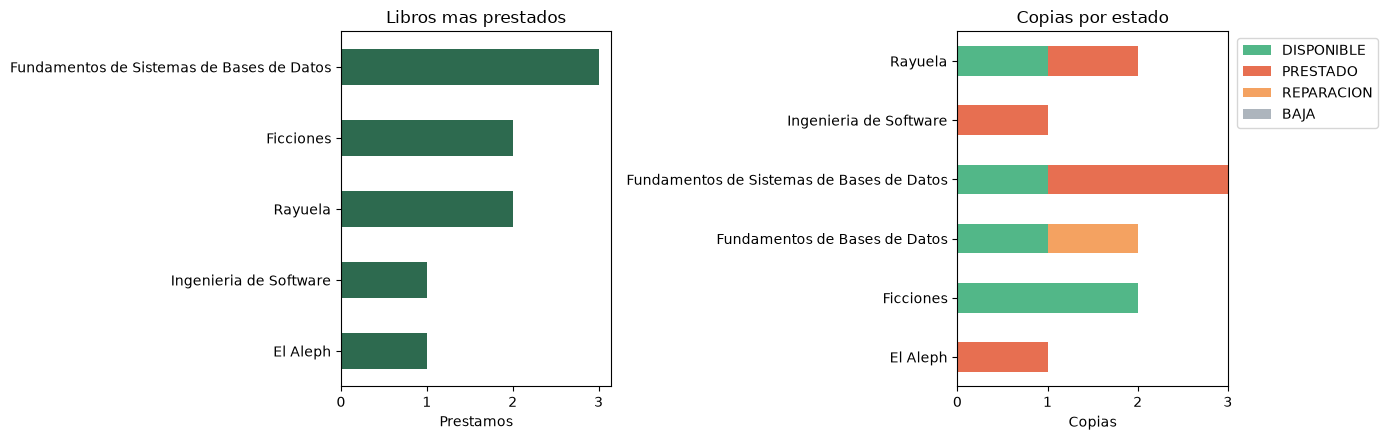

In [25]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(14, 4.5))

ranking.set_index("titulo")["veces"].sort_values().plot.barh(ax=izq, color="#2d6a4f")
izq.set_title("Libros mas prestados")
izq.set_xlabel("Prestamos")
izq.set_ylabel("")

estado_actual = tabla([
    {"titulo": l["titulo"], **dao.disponibilidad(l["lib_id"])} for l in dao.listar_libros()
]).set_index("titulo")
estado_actual.plot.barh(ax=der, stacked=True,
                        color=["#52b788", "#e76f51", "#f4a261", "#adb5bd"])
der.set_title("Copias por estado")
der.set_xlabel("Copias")
der.set_ylabel("")
der.legend(loc="upper left", bbox_to_anchor=(1.01, 1))

for eje in (izq, der):
    eje.xaxis.get_major_locator().set_params(integer=True)

plt.tight_layout()
plt.show()

In [26]:
# como estaba al principio y como quedo
tabla([resumen_inicial, dao.resumen()]).T.set_axis(["inicio", "ahora"], axis=1)

,inicio,ahora
socios_activos,5,5
libros,6,6
prestamos_activos,2,5
prestamos_vencidos,1,0
multas_pendientes,1,1


## 6. MongoDB: resenas y auditoria

Las resenas van en Mongo porque cada una tiene una lista de etiquetas de largo
variable. La auditoria tambien, porque cada tipo de evento guarda datos distintos.

Para agregar una resena:
- el puntaje va de 1 a 5
- el socio tiene que haber pedido el libro (eso se consulta en Oracle)
- un socio no puede resenar dos veces el mismo libro (indice unique en Mongo)

In [27]:
tabla(dao.resenas_de_libro(4), ["socio", "puntaje", "comentario", "etiquetas"])

,socio,puntaje,comentario,etiquetas
0,"Andrada, Sofia",3,Completo pero denso; mejor con el apunte.,"[bases-de-datos, denso]"
1,"Herrera, Lucia",5,Muy claro para normalizacion y SQL.,"[bases-de-datos, teoria, recomendado]"


In [28]:
# asi queda guardado un documento
from pprint import pprint
pprint(dao.resenas_de_libro(4)[0], sort_dicts=False)

{'_id': '6ae67e292b5aece07aad6ac3',
 'lib_id': 4,
 'soc_id': 3,
 'socio': 'Andrada, Sofia',
 'titulo': 'Fundamentos de Sistemas de Bases de Datos',
 'puntaje': 3,
 'comentario': 'Completo pero denso; mejor con el apunte.',
 'etiquetas': ['bases-de-datos', 'denso'],
 'fecha': datetime.datetime(2026, 10, 31, 20, 47, 53, 894000)}


In [29]:
dao.agregar_resena(soc_id=juan, lib_id=1, puntaje=5,
                   comentario="Lo lei en una semana, muy recomendable.",
                   etiquetas=["Clasico", "cuentos", "Literatura-Argentina"])
print("Juan reseno Ficciones")

debe_fallar("Juan resena El Aleph (nunca lo pidio)",
            lambda: dao.agregar_resena(soc_id=juan, lib_id=2, puntaje=4))
debe_fallar("Juan resena Ficciones otra vez",
            lambda: dao.agregar_resena(soc_id=juan, lib_id=1, puntaje=3))
debe_fallar("Puntaje 9",
            lambda: dao.agregar_resena(soc_id=2, lib_id=2, puntaje=9))

dao.agregar_resena(soc_id=2, lib_id=2, puntaje=4, comentario="Corto e intenso.",
                   etiquetas=["cuentos", "literatura-argentina"])
print("Quiroga reseno El Aleph")

Juan reseno Ficciones
Juan resena El Aleph (nunca lo pidio) -> Solo puede resenar un libro quien lo pidio prestado
Juan resena Ficciones otra vez -> Ese socio ya reseno ese libro (usar actualizar_resena)
Puntaje 9 -> El puntaje va de 1 a 5
Quiroga reseno El Aleph


In [30]:
# busca dentro de la lista de etiquetas (se guardan en minuscula)
tabla(dao.buscar_resenas_por_etiqueta("literatura-argentina"), ["titulo", "socio", "puntaje", "etiquetas"])

,titulo,socio,puntaje,etiquetas
0,Ficciones,"Vega, Carlos",5,"[clasico, cuentos, literatura-argentina]"
1,Ficciones,"Paz, Juan",5,"[clasico, cuentos, literatura-argentina]"
2,Rayuela,"Quiroga, Martin",4,"[novela, literatura-argentina]"
3,El Aleph,"Quiroga, Martin",4,"[cuentos, literatura-argentina]"


In [31]:
# Sofia cambia su resena del libro 4
def promedio_libro_4():
    return next(m["promedio"] for m in dao.mejores_libros() if m["lib_id"] == 4)

print("Antes: ", [r["puntaje"] for r in dao.resenas_de_libro(4)], "promedio", promedio_libro_4())
dao.actualizar_resena(3, 4, puntaje=4, comentario="Releido con el apunte, mucho mejor.",
                      etiquetas=["bases-de-datos", "teoria"])
print("Despues:", [r["puntaje"] for r in dao.resenas_de_libro(4)], "promedio", promedio_libro_4())

Antes:  [3, 5] promedio 4.0
Despues: [4, 5] promedio 4.5


In [32]:
# agregaciones: promedio por libro y etiquetas mas usadas
from IPython.display import display
display(tabla(dao.mejores_libros()))
display(tabla(dao.etiquetas_populares()))

,lib_id,titulo,promedio,resenas
0,1,Ficciones,5.0,2
1,4,Fundamentos de Sistemas de Bases de Datos,4.5,2
2,2,El Aleph,4.0,1
3,3,Rayuela,4.0,1


,etiqueta,cantidad
0,literatura-argentina,4
1,cuentos,3
2,bases-de-datos,2
3,clasico,2
4,teoria,2
5,novela,1
6,recomendado,1


In [33]:
# ultimos eventos de la auditoria, cada uno con sus propios campos
eventos = dao.auditoria(limite=12)
columnas = list(dict.fromkeys(campo for e in eventos for campo in e))
tabla([{c: e.get(c, "") for c in columnas} for e in eventos])

,evento,fecha,pre_id,soc_id,lib_id,eje_id,vence,mul_id,dias_atraso,multa,dni,tipo
0,PRESTAMO,2026-10-31 20:47:54.583,9,2,2,3,2026-11-14,,,,,
1,MULTA_PAGADA,2026-10-31 20:47:54.571,,,,,,2,,,,
2,DEVOLUCION,2026-10-31 20:47:54.523,5,6,1,,,,0,0,,
3,DEVOLUCION,2026-10-31 20:47:54.511,2,2,3,,,,6,3000,,
4,BAJA_SOCIO,2026-10-31 20:47:54.445,,5,,,,,,,,
5,PRESTAMO,2026-10-31 20:47:54.430,8,4,6,11,2026-11-14,,,,,
6,PRESTAMO,2026-10-31 20:47:54.415,7,6,4,7,2026-11-14,,,,,
7,PRESTAMO,2026-10-31 20:47:54.399,6,6,3,5,2026-11-14,,,,,
8,PRESTAMO,2026-10-31 20:47:54.353,5,6,1,1,2026-11-14,,,,,
9,ALTA_SOCIO,2026-10-31 20:47:54.276,,6,,,,,,,45000111,ALUMNO


In [34]:
tabla(dao.auditoria_por_evento())

,evento,cantidad,ultimo
0,PRESTAMO,5,2026-10-31 20:47:54.583
1,DEVOLUCION,2,2026-10-31 20:47:54.523
2,BAJA_SOCIO,1,2026-10-31 20:47:54.445
3,ALTA_SOCIO,1,2026-10-31 20:47:54.276
4,MULTA_PAGADA,1,2026-10-31 20:47:54.571


Desde la consola de mongo:
`docker exec -it mongo-biblio mongosh -u biblio -p biblio123 --quiet biblioteca`

```js
db.resenas.find({lib_id: 4})
db.resenas.find({etiquetas: "cuentos"})
db.resenas.aggregate([{$group: {_id: "$lib_id", promedio: {$avg: "$puntaje"}}}])
db.resenas.getIndexes()
db.auditoria.find().sort({fecha: -1}).limit(5)
```

## 7. Redis: ranking, cache y contadores

Claves que usa el proyecto:
- `ranking:prestamos`: sorted set, se le suma 1 al libro en cada prestamo (ZINCRBY)
- `disponibilidad:libro:<id>`: hash con las copias por estado, dura 60 segundos
- `actividad:<fecha>`: hash con los prestamos y devoluciones del dia

Si Redis se pierde se puede volver a armar desde Oracle con `dao.inicializar_nosql()`.

In [35]:
# ttl -1 = no vence
tabla(dao.claves_redis())

,clave,tipo,ttl_segundos
0,actividad:2026-10-31,hash,604799
1,disponibilidad:libro:1,hash,60
2,disponibilidad:libro:2,hash,60
3,disponibilidad:libro:3,hash,60
4,disponibilidad:libro:4,hash,60
5,disponibilidad:libro:5,hash,59
6,disponibilidad:libro:6,hash,59
7,ranking:prestamos,zset,-1


In [36]:
# el ranking de redis tiene que dar lo mismo que contar en oracle
redis_rank = tabla(dao.ranking_tiempo_real(top=10))[["titulo", "prestamos"]]
oracle_rank = tabla(dao.libros_mas_prestados(top=10))[["titulo", "veces"]]
redis_rank.merge(oracle_rank, on="titulo").rename(columns={"prestamos": "redis", "veces": "oracle"})

,titulo,redis,oracle
0,Fundamentos de Sistemas de Bases de Datos,3,3
1,Rayuela,2,2
2,Ficciones,2,2
3,Ingenieria de Software,1,1
4,El Aleph,1,1


In [37]:
# cache: la primera vez lee de oracle y guarda en redis, la segunda sale de redis
import time
from db_models import cache

dao.redis.delete(cache.disponibilidad(5))   # la borro para arrancar sin cache
for intento in (1, 2):
    inicio = time.perf_counter()
    dato = dao.disponibilidad(5)
    ms = (time.perf_counter() - inicio) * 1000
    print(f"Lectura {intento}: {dato} desde {dao.ultima_fuente} ({ms:.1f} ms)")
print("Vence en", dao.redis.ttl(cache.disponibilidad(5)), "segundos")

Lectura 1: {'DISPONIBLE': 1, 'PRESTADO': 0, 'REPARACION': 1, 'BAJA': 0} desde oracle (4.0 ms)
Lectura 2: {'DISPONIBLE': 1, 'PRESTADO': 0, 'REPARACION': 1, 'BAJA': 0} desde redis (0.6 ms)
Vence en 60 segundos


In [38]:
# al prestar se borra la clave, entonces la siguiente lectura va a oracle
dao.prestar_libro(soc_id=1, lib_id=5)
print(dao.disponibilidad(5), "desde", dao.ultima_fuente)

{'DISPONIBLE': 0, 'PRESTADO': 1, 'REPARACION': 1, 'BAJA': 0} desde oracle


In [39]:
dao.actividad_de_hoy()

{'prestamos': 6, 'devoluciones': 2}

In [40]:
# los comandos de redis directo
print("ZREVRANGE ranking:prestamos 0 -1 WITHSCORES:",
      dao.redis.zrevrange(cache.RANKING_PRESTAMOS, 0, -1, withscores=True))
print("HGETALL disponibilidad:libro:5:", dao.redis.hgetall(cache.disponibilidad(5)))
print("TYPE ranking:prestamos:", dao.redis.type(cache.RANKING_PRESTAMOS))

ZREVRANGE ranking:prestamos 0 -1 WITHSCORES: [('4', 3.0), ('3', 2.0), ('1', 2.0), ('6', 1.0), ('5', 1.0), ('2', 1.0)]
HGETALL disponibilidad:libro:5: {'DISPONIBLE': '0', 'PRESTADO': '1', 'REPARACION': '1', 'BAJA': '0'}
TYPE ranking:prestamos: zset


Desde redis-cli (`docker exec -it redis-biblio redis-cli`):

```
KEYS *
ZREVRANGE ranking:prestamos 0 -1 WITHSCORES
HGETALL disponibilidad:libro:5
TTL disponibilidad:libro:5
```

## 8. SQL que genera SQLAlchemy

Con `echo=True` se ve cada sentencia que se manda a Oracle. Los valores van
como parametros (`:soc_id_1`), no pegados al texto, asi que no hay inyeccion SQL.

In [41]:
with BibliotecaDAO(echo=True) as dao_debug:
    dao_debug.historial_socio(1)

2026-10-31 20:47:55,292 INFO sqlalchemy.engine.Engine select sys_context( 'userenv', 'current_schema' ) from dual


2026-10-31 20:47:55,293 INFO sqlalchemy.engine.Engine [raw sql] {}


2026-10-31 20:47:55,301 INFO sqlalchemy.engine.Engine BEGIN (implicit)


2026-10-31 20:47:55,301 INFO sqlalchemy.engine.Engine SELECT prestamos.pre_id, socios.soc_id, socios.apellido || :apellido_1 || socios.nombre AS socio, libros.titulo, ejemplares.codigo_inventario, prestamos.fecha_prestamo, prestamos.fecha_vencimiento, prestamos.fecha_devolucion 
FROM prestamos JOIN socios ON socios.soc_id = prestamos.soc_id JOIN ejemplares ON ejemplares.eje_id = prestamos.eje_id JOIN libros ON libros.lib_id = ejemplares.lib_id 
WHERE prestamos.soc_id = :soc_id_1 ORDER BY prestamos.fecha_prestamo DESC, prestamos.pre_id DESC


2026-10-31 20:47:55,302 INFO sqlalchemy.engine.Engine [generated in 0.00112s] {'apellido_1': ', ', 'soc_id_1': 1}


2026-10-31 20:47:55,305 INFO sqlalchemy.engine.Engine ROLLBACK


## 9. El mismo DAO con SQLite

Sin cambiar nada del DAO, solo la url de conexion.

In [42]:
import demo_sqlite
demo_sqlite.main()

with BibliotecaDAO("sqlite:///biblio_demo.db", usar_nosql=False) as dao_sqlite:
    print("Motor:", dao_sqlite.engine.dialect.name)
    print(tabla(dao_sqlite.listar_libros(), ["lib_id", "titulo", "autor"]).to_string(index=False))

Base demo creada: biblio_demo.db
{'socios_activos': 5, 'libros': 6, 'prestamos_activos': 2, 'prestamos_vencidos': 1, 'multas_pendientes': 1}
Motor: sqlite
 lib_id                                    titulo                autor
      2                                  El Aleph    Jorge Luis Borges
      1                                 Ficciones    Jorge Luis Borges
      5             Fundamentos de Bases de Datos Abraham Silberschatz
      4 Fundamentos de Sistemas de Bases de Datos        Ramez Elmasri
      6                    Ingenieria de Software      Ian Sommerville
      3                                   Rayuela       Julio Cortazar


## 10. Probar una consulta nueva

Antes de agregarla al proyecto se puede probar aca. Ejemplo: libros que nunca
se prestaron. Si anda, va como metodo en `db_models/libros.py`, despues en
`dao.py` y si hace falta una opcion en `main.py`.

In [43]:
from sqlalchemy import select, func
from db_models.libros import libros
from db_models.ejemplares import ejemplares
from db_models.prestamos import prestamos

consulta = (
    select(libros.c.lib_id, libros.c.titulo)
    .select_from(libros)
    .outerjoin(ejemplares, ejemplares.c.lib_id == libros.c.lib_id)
    .outerjoin(prestamos, prestamos.c.eje_id == ejemplares.c.eje_id)
    .group_by(libros.c.lib_id, libros.c.titulo)
    .having(func.count(prestamos.c.pre_id) == 0)
    .order_by(libros.c.titulo)
)
print(consulta, "\n")
tabla(dao._todos(consulta))

SELECT libros.lib_id, libros.titulo 
FROM libros LEFT OUTER JOIN ejemplares ON ejemplares.lib_id = libros.lib_id LEFT OUTER JOIN prestamos ON prestamos.eje_id = ejemplares.eje_id GROUP BY libros.lib_id, libros.titulo 
HAVING count(prestamos.pre_id) = :count_1 ORDER BY libros.titulo 



""


In [44]:
print(dao.resumen_nosql())
dao.close()

{'resenas (Mongo)': 6, 'eventos de auditoria (Mongo)': 11, 'libros en el ranking (Redis)': 6, 'claves del proyecto (Redis)': 8}
